In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn imbalanced-learn xgboost

In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    StratifiedKFold
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTENC

from xgboost import XGBClassifier

RANDOM_STATE = 42

print("All libraries imported successfully.")

All libraries imported successfully.


In [3]:
df = pd.read_csv("/content/WA_Fn-UseC_-Telco-Customer-Churn.csv")

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully.
Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.shape


(7043, 21)

In [6]:
df.duplicated()

,0
0,False
1,False
2,False
3,False
4,False
...,...
7038,False
7039,False
7040,False
7041,False


In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [10]:
df.head(10)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes
6,1452-KIOVK,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,...,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.4,No
7,6713-OKOMC,Female,0,No,No,10,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,No,Mailed check,29.75,301.9,No
8,7892-POOKP,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,...,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes
9,6388-TABGU,Male,0,No,Yes,62,Yes,No,DSL,Yes,...,No,No,No,No,One year,No,Bank transfer (automatic),56.15,3487.95,No


In [11]:
df.tail(5)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


In [12]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe(include="all").T)

print("\nMissing values:")
display(df.isnull().sum().sort_values(ascending=False))

print("\nDuplicate rows:", df.duplicated().sum())

Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecur

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,3186-AJIEK,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Missing values:


,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0



Duplicate rows: 0


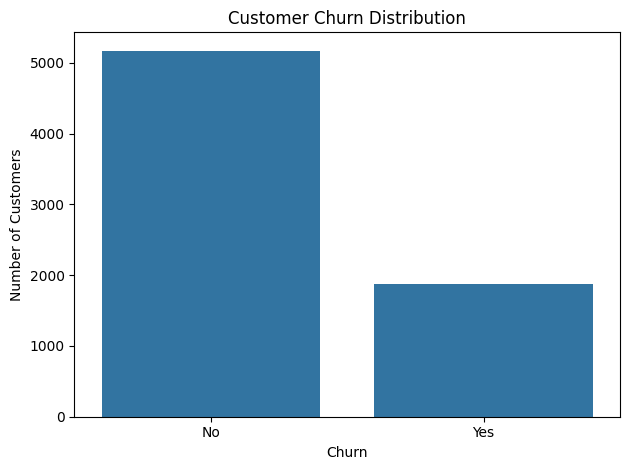

In [13]:
sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

In [14]:
df = df.copy()

df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"].astype(str).str.strip(),
    errors="coerce"
)

df["Churn"] = df["Churn"].astype(str).str.strip()

df = df[df["Churn"].isin(["Yes", "No"])].copy()

print("TotalCharges missing values:",
      df["TotalCharges"].isnull().sum())

print("\nTarget values:")
print(df["Churn"].value_counts())

TotalCharges missing values: 11

Target values:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [15]:
X = df.drop(columns=["Churn", "customerID"], errors="ignore")

y = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

print("Input feature shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())
print("\nTarget distribution:")
print(y.value_counts())

Input feature shape: (7043, 19)
Target shape: (7043,)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65



Target distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining class proportions:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting class proportions:")
print(y_test.value_counts(normalize=True).round(3))

Training samples: 5634
Testing samples: 1409

Training class proportions:
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64

Testing class proportions:
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64


In [17]:
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numeric features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Numeric features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [18]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features)
    ],
    remainder="drop"
)

print("Preprocessing pipelines created.")

Preprocessing pipelines created.


In [19]:
rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

rf_pipeline.fit(X_train, y_train)

print("Random Forest training completed.")

Random Forest training completed.


In [20]:
negative_count = int((y_train == 0).sum())
positive_count = int((y_train == 1).sum())

scale_pos_weight = negative_count / positive_count

print("Non-churn customers:", negative_count)
print("Churn customers:", positive_count)
print("Initial scale_pos_weight:", round(scale_pos_weight, 3))

Non-churn customers: 4139
Churn customers: 1495
Initial scale_pos_weight: 2.769


In [21]:
xgb_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=4,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=scale_pos_weight,
        eval_metric="logloss",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

xgb_pipeline.fit(X_train, y_train)

print("XGBoost training completed.")

XGBoost training completed.


In [24]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

rf_parameters = {
    "classifier__n_estimators": [200, 300],
    "classifier__max_depth": [None, 15],
    "classifier__min_samples_leaf": [1, 3]
}

rf_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_parameters,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    refit=True,
    verbose=1
)

rf_search.fit(X_train, y_train)

best_rf = rf_search.best_estimator_

print("Best Random Forest parameters:")
print(rf_search.best_params_)
print("Best cross-validation ROC-AUC:",
      round(rf_search.best_score_, 4))

Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best Random Forest parameters:
{'classifier__max_depth': 15, 'classifier__min_samples_leaf': 3, 'classifier__n_estimators': 300}
Best cross-validation ROC-AUC: 0.8423


In [25]:


xgb_parameters = {
    "classifier__n_estimators": [200, 300],
    "classifier__max_depth": [3, 5],
    "classifier__learning_rate": [0.03, 0.1]
}

xgb_search = GridSearchCV(
    estimator=xgb_pipeline,
    param_grid=xgb_parameters,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    refit=True,
    verbose=1
)

xgb_search.fit(X_train, y_train)

best_xgb = xgb_search.best_estimator_

print("Best XGBoost parameters:")
print(xgb_search.best_params_)
print("Best cross-validation ROC-AUC:",
      round(xgb_search.best_score_, 4))

Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best XGBoost parameters:
{'classifier__learning_rate': 0.03, 'classifier__max_depth': 3, 'classifier__n_estimators': 200}
Best cross-validation ROC-AUC: 0.8494


In [26]:
rf_predictions = best_rf.predict(X_test)
xgb_predictions = best_xgb.predict(X_test)

rf_probabilities = best_rf.predict_proba(X_test)[:, 1]
xgb_probabilities = best_xgb.predict_proba(X_test)[:, 1]

def evaluate_model(name, y_true, predictions, probabilities):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1-Score": f1_score(
            y_true, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_true, probabilities)
    }

results = pd.DataFrame([
    evaluate_model(
        "Random Forest",
        y_test,
        rf_predictions,
        rf_probabilities
    ),
    evaluate_model(
        "XGBoost",
        y_test,
        xgb_predictions,
        xgb_probabilities
    )
]).set_index("Model")

display(results.round(4))

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Random Forest,0.7743,0.5609,0.6898,0.6187,0.8393
XGBoost,0.7480,0.5162,0.8075,0.6298,0.8476


In [27]:
print("RANDOM FOREST CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    rf_predictions,
    target_names=["Stay", "Churn"],
    zero_division=0
))

print("XGBOOST CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    xgb_predictions,
    target_names=["Stay", "Churn"],
    zero_division=0
))

RANDOM FOREST CLASSIFICATION REPORT
              precision    recall  f1-score   support

        Stay       0.88      0.80      0.84      1035
       Churn       0.56      0.69      0.62       374

    accuracy                           0.77      1409
   macro avg       0.72      0.75      0.73      1409
weighted avg       0.79      0.77      0.78      1409

XGBOOST CLASSIFICATION REPORT
              precision    recall  f1-score   support

        Stay       0.91      0.73      0.81      1035
       Churn       0.52      0.81      0.63       374

    accuracy                           0.75      1409
   macro avg       0.71      0.77      0.72      1409
weighted avg       0.81      0.75      0.76      1409



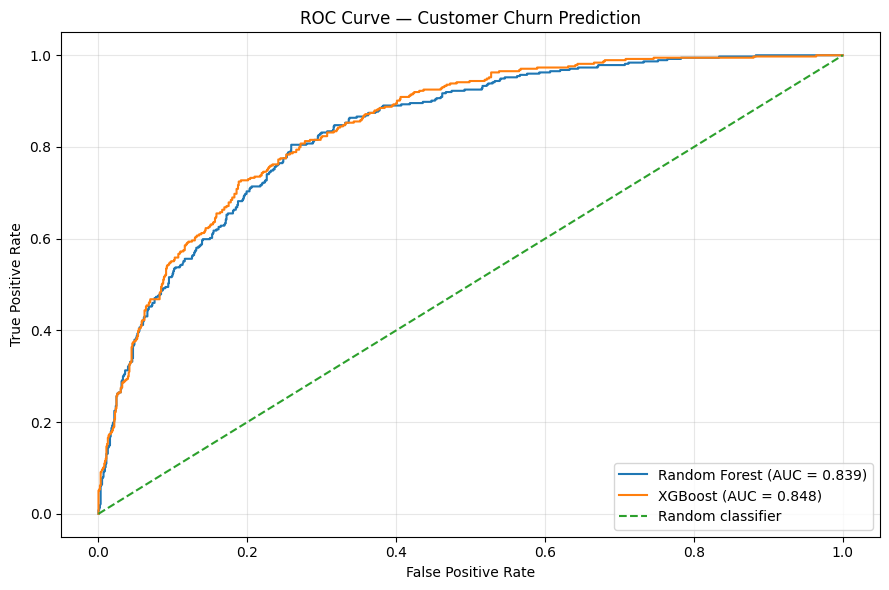

In [28]:
rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_probabilities)
xgb_fpr, xgb_tpr, _ = roc_curve(y_test, xgb_probabilities)

rf_auc = roc_auc_score(y_test, rf_probabilities)
xgb_auc = roc_auc_score(y_test, xgb_probabilities)

plt.figure(figsize=(9, 6))

plt.plot(
    rf_fpr, rf_tpr,
    label=f"Random Forest (AUC = {rf_auc:.3f})"
)

plt.plot(
    xgb_fpr, xgb_tpr,
    label=f"XGBoost (AUC = {xgb_auc:.3f})"
)

plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Customer Churn Prediction")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [29]:
for model_name, auc in [
    ("Random Forest", rf_auc),
    ("XGBoost", xgb_auc)
]:
    status = "Target achieved" if auc > 0.80 else "Target not achieved"
    print(f"{model_name}: ROC-AUC = {auc:.4f} — {status}")

Random Forest: ROC-AUC = 0.8393 — Target achieved
XGBoost: ROC-AUC = 0.8476 — Target achieved


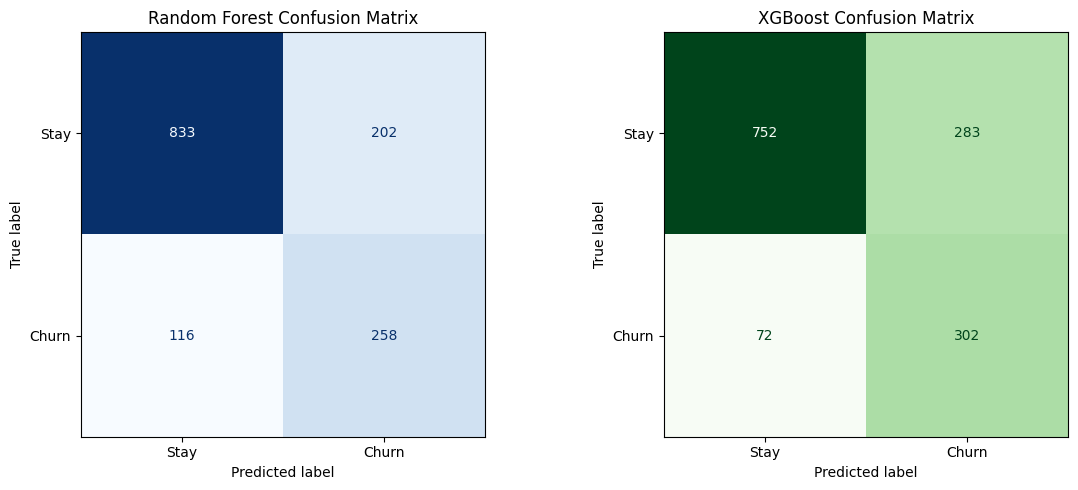

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_predictions,
    labels=[0, 1],
    display_labels=["Stay", "Churn"],
    cmap="Blues",
    ax=axes[0],
    colorbar=False
)

axes[0].set_title("Random Forest Confusion Matrix")

ConfusionMatrixDisplay.from_predictions(
    y_test,
    xgb_predictions,
    labels=[0, 1],
    display_labels=["Stay", "Churn"],
    cmap="Greens",
    ax=axes[1],
    colorbar=False
)

axes[1].set_title("XGBoost Confusion Matrix")

plt.tight_layout()
plt.show()

In [31]:
def get_top_features(fitted_pipeline, top_n=10):
    fitted_preprocessor = fitted_pipeline.named_steps["preprocessor"]
    fitted_classifier = fitted_pipeline.named_steps["classifier"]

    feature_names = fitted_preprocessor.get_feature_names_out()
    importances = fitted_classifier.feature_importances_

    importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Importance": importances
    })

    importance_df["Feature"] = (
        importance_df["Feature"]
        .str.replace("numeric__", "", regex=False)
        .str.replace("categorical__", "", regex=False)
    )

    return importance_df.sort_values(
        "Importance",
        ascending=False
    ).head(top_n)

,Feature,Importance
1,tenure,0.126818
3,TotalCharges,0.113686
36,Contract_Month-to-month,0.108398
2,MonthlyCharges,0.087428
18,OnlineSecurity_No,0.054920
38,Contract_Two year,0.053843
27,TechSupport_No,0.043804
16,InternetService_Fiber optic,0.041550
43,PaymentMethod_Electronic check,0.034645
21,OnlineBackup_No,0.018465


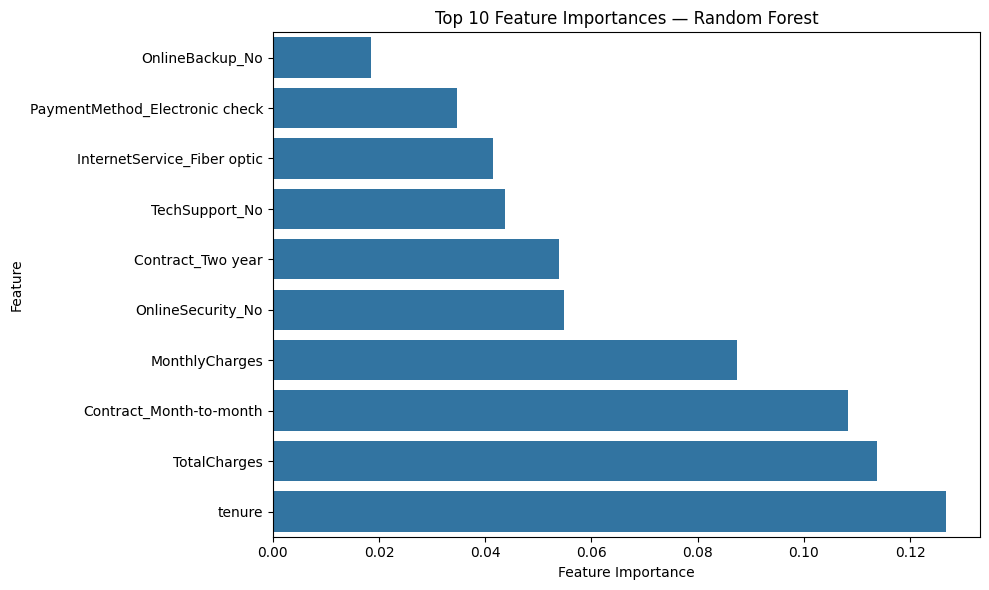

In [32]:
rf_top_features = get_top_features(best_rf)

display(rf_top_features)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=rf_top_features.sort_values("Importance"),
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Feature Importances — Random Forest")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

,Feature,Importance
36,Contract_Month-to-month,0.314962
18,OnlineSecurity_No,0.095384
27,TechSupport_No,0.065193
16,InternetService_Fiber optic,0.063444
15,InternetService_DSL,0.042295
38,Contract_Two year,0.039815
37,Contract_One year,0.031846
19,OnlineSecurity_No internet service,0.030961
43,PaymentMethod_Electronic check,0.029779
17,InternetService_No,0.028682


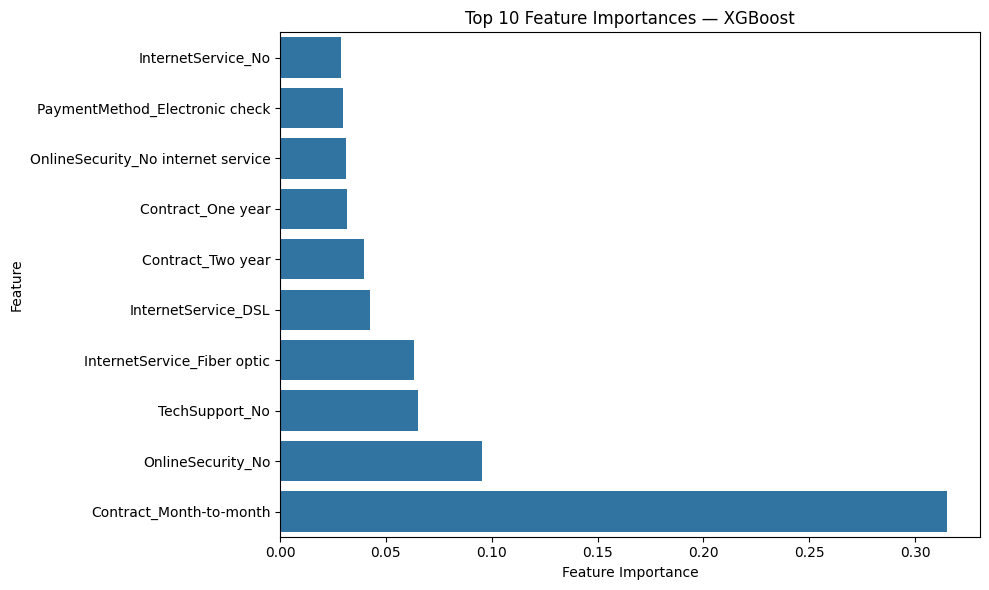

In [33]:
xgb_top_features = get_top_features(best_xgb)

display(xgb_top_features)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=xgb_top_features.sort_values("Importance"),
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Feature Importances — XGBoost")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [34]:
best_model_name = results["ROC-AUC"].idxmax()
best_auc = results.loc[best_model_name, "ROC-AUC"]

print("FINAL MODEL COMPARISON")
display(results.sort_values("ROC-AUC", ascending=False).round(4))

print("\nBEST MODEL:", best_model_name)
print("BEST ROC-AUC:", round(best_auc, 4))

if best_auc > 0.80:
    print("The ROC-AUC target greater than 0.80 was achieved.")
else:
    print("The ROC-AUC target greater than 0.80 was not achieved.")

FINAL MODEL COMPARISON


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
XGBoost,0.7480,0.5162,0.8075,0.6298,0.8476
Random Forest,0.7743,0.5609,0.6898,0.6187,0.8393



BEST MODEL: XGBoost
BEST ROC-AUC: 0.8476
The ROC-AUC target greater than 0.80 was achieved.


In [35]:
print("\nPROJECT CONCLUSION")

print(
    f"The project compared Random Forest and XGBoost "
    f"for telecom customer churn prediction. "
    f"{best_model_name} achieved the highest test ROC-AUC "
    f"of {best_auc:.4f}."
)

print(
    "Missing values were handled through preprocessing pipelines, "
    "categorical variables were encoded using OneHotEncoder, "
    "and class imbalance was addressed using class weighting."
)

print(
    "The ROC curves compared model discrimination, confusion matrices "
    "showed classification errors, and feature-importance plots identified "
    "the most influential features according to each tree model."
)

print(
    "The final model should be selected using ROC-AUC together with "
    "precision, recall, F1-score, the cost of false negatives, "
    "and the business objective."
)


PROJECT CONCLUSION
The project compared Random Forest and XGBoost for telecom customer churn prediction. XGBoost achieved the highest test ROC-AUC of 0.8476.
Missing values were handled through preprocessing pipelines, categorical variables were encoded using OneHotEncoder, and class imbalance was addressed using class weighting.
The ROC curves compared model discrimination, confusion matrices showed classification errors, and feature-importance plots identified the most influential features according to each tree model.
The final model should be selected using ROC-AUC together with precision, recall, F1-score, the cost of false negatives, and the business objective.


In [37]:
results.to_csv("customer_churn_model_comparison.csv")

rf_top_features.to_csv(
    "random_forest_top_features.csv",
    index=False
)

xgb_top_features.to_csv(
    "xgboost_top_features.csv",
    index=False
)

print("Results saved successfully.")

Results saved successfully.
